# 05 — Uplift Modeling: Determining Who to Target
### SmartTel Retention Intelligence — (Future Work / Experimental Extension)

**Input:** `telco_features_scored_latest.parquet` (produced by `03_classification_benchmarking.ipynb`)

>  The core system (Modules 1–3, 6–8) is complete and deployable without this module. Everything below runs on a **simulated** retention pilot, because the source dataset contains no retention-offer data. The notebook is built to answer three practical questions rather than to show that uplift modeling "wins":
> 1. Can standard uplift learners recover a known response pattern from a pilot of this size?
> 2. Under what conditions does uplift targeting beat the churn-risk targeting we already have from Module 3?
> 3. How large would a real randomized pilot need to be?

**Scope of this notebook** :
1. Design a semi-synthetic randomized pilot with an explicit, documented, planted response structure
2. Fit T-learner and X-learner uplift models and evaluate them with Qini curves and ground-truth recovery
3. Compare uplift targeting against churn-risk targeting, including a sweep over how strongly the two diverge
4. Estimate how pilot size changes the answer
5. Classify customers into **Persuadables, Sure Things, Lost Causes, Sleeping Dogs**, and validate those labels against ground truth
6. Preview the targeting trade-off (customers saved vs. backfires) as a function of campaign budget
7. Stress-test the pipeline when offer assignment is *not* randomized
8. Persist clearly-labeled experimental outputs


## What This Module Can and Cannot Claim

**Why a simulation is unavoidable.** Uplift modeling needs data in which some customers received a retention offer and others did not, with assignment that is random (or at least free of hidden bias), and churn observed afterward. Every `Churn` label in the IBM Telco dataset was observed under "no recorded offer". Pretending `Churn` is the outcome of a randomly assigned synthetic offer would embed **zero** treatment effect (the offer would be independent of the outcome by construction), so any model fit to it would simply learn noise.

**What this notebook does instead (a semi-synthetic design).** It keeps the real customers and their real covariates, uses Module 3's calibrated churn probability as each customer's no-offer churn risk, and then **plants an explicit, documented response structure** on top. It simulates a randomized pilot from that structure and asks whether standard uplift methods can recover it, and whether acting on it would beat the churn-risk targeting that Modules 1–3 already support.

**What it can claim**
- The uplift pipeline (simulate → fit → evaluate → segment → decide) works end to end and is ready to be pointed at real pilot data
- How well T- and X-learners recover a *known* effect at roughly this sample size
- Under which conditions uplift targeting beats risk targeting, and under which it does not
- A planning estimate of how large a real pilot would need to be

**What it cannot claim**
- Anything about how real SmartTel customers respond to real offers. Every response effect here is an assumption written by the analyst, so any "uplift wins" result in a given scenario is true **by construction**, and is reported next to scenarios where it is not
- That the four-segment labels are reliable for real customers. They are validated here only against a simulation we control

**Uplift sign convention used throughout:** *uplift = reduction in churn probability if the customer is contacted* (equivalently, the increase in retention probability). Positive values mean the offer helps; negative values mean it backfires.


## 1. Setup & Imports

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import date

from scipy.optimize import brentq
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier, XGBRegressor

from sklift.metrics import qini_auc_score, qini_curve, uplift_at_k

# scikit-uplift 0.5.1 calls a scikit-learn helper that is deprecated in scikit-learn 1.8.
# The warning is harmless; it is silenced only to keep the notebook output readable.
warnings.filterwarnings("ignore", message=".*stable_cumsum.*")

pd.set_option("display.max_columns", 100)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

FEATURE_STORE_DIR = Path("../data/feature_store")
CONFIGS_DIR = Path("../configs")
CONFIGS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


## 2. Load Scored Dataset

In [2]:
df = pd.read_parquet(FEATURE_STORE_DIR / "telco_features_scored_latest.parquet")
n = len(df)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Mean calibrated churn probability: {df['churn_probability'].mean():.4f}")
df[["customerID", "Contract", "tenure", "MonthlyCharges", "persona_name", "churn_probability"]].head(15)


Shape: 7,043 rows x 29 columns
Mean calibrated churn probability: 0.2665


,customerID,Contract,tenure,MonthlyCharges,persona_name,churn_probability
0,7590-VHVEG,Month-to-month,1,29.85,New & Price-Sensitive,0.640019
1,5575-GNVDE,One year,34,56.95,New & Price-Sensitive,0.054867
2,3668-QPYBK,Month-to-month,2,53.85,New & Price-Sensitive,0.405564
3,7795-CFOCW,One year,45,42.30,New & Price-Sensitive,0.059328
4,9237-HQITU,Month-to-month,2,70.70,New & Price-Sensitive,0.574892
5,9305-CDSKC,Month-to-month,8,99.65,New & High-Risk,0.961530
6,1452-KIOVK,Month-to-month,22,89.10,New & High-Risk,0.449048
7,6713-OKOMC,Month-to-month,10,29.75,New & Price-Sensitive,0.145913
8,7892-POOKP,Month-to-month,28,104.80,New & High-Risk,0.626501
9,6388-TABGU,One year,62,56.15,New & Price-Sensitive,0.022516


## 3. Simulation Design: A Semi-Synthetic Randomized Pilot

### 3.1 The planted response structure

Four quantities define the simulation. All are explicit so that every result below can be traced back to an assumption.

| Quantity | Definition | Intent |
|---|---|---|
| **Baseline churn risk** `p0(x)` | Module 3's calibrated churn probability | Keeps the real covariate-to-churn relationship |
| **Save probability** `s(x)` | Chance an offer *saves* a customer who would otherwise churn: `sigmoid(a + 0.6·price_gap − κ·z_risk)`, where `price_gap = z(MonthlyCharges) − 0.6·z(services_count)` | Price-sensitive customers (paying a lot for little) are more persuadable. `κ` is the **divergence dial**: how strongly persuadability *falls* as churn risk rises ("committed leavers" who have already decided) |
| **Backfire probability** `h(x)` | Chance contact *triggers* churn in a customer who would have stayed: `sigmoid(−4.2 + 0.7·TwoYear + 0.3·z(tenure) − 0.2·z(services))` | Loyal, long-tenure, low-engagement customers are most likely to be prompted to re-evaluate; about 2% on average |
| **Assignment** `W` | Randomized, `P(W=1) = 0.5` | Mimics a randomized pilot (the design a real team should run) |

The intercept `a` is solved so that the **average save rate is held at 22%** regardless of `κ`. This isolates *divergence* from overall effect size when `κ` is varied later.

**Potential outcomes.** Draw `Y0 ~ Bernoulli(p0)` (churn with no offer). If `Y0 = 1`, then `Y1 = 0` with probability `s` (saved), otherwise `Y1 = 1`. If `Y0 = 0`, then `Y1 = 1` with probability `h` (backfire), otherwise `Y1 = 0`. The observed outcome is `Y1` for treated customers and `Y0` for controls. This structure maps directly onto the four uplift segments:

| | `Y0` (no offer) | `Y1` (offer) |
|---|---|---|
| **Persuadable** | churns | stays |
| **Sure Thing** | stays | stays |
| **Lost Cause** | churns | churns |
| **Sleeping Dog** | stays | churns |

**True individual uplift (known only because this is a simulation):** `τ(x) = p0·s − (1 − p0)·h`.



In [3]:
sig = lambda z: 1 / (1 + np.exp(-z))
logit = lambda p: np.log(p / (1 - p))

def zscore(series):
    return ((series - series.mean()) / series.std()).to_numpy()

p0 = df["churn_probability"].to_numpy()
z_tenure = zscore(df["tenure"])
z_charges = zscore(df["MonthlyCharges"])
z_services = zscore(df["services_count"])
is_two_year = (df["Contract"] == "Two year").to_numpy().astype(float)
is_month_to_month = (df["Contract"] == "Month-to-month").to_numpy().astype(float)

price_gap = z_charges - 0.6 * z_services
z_risk = zscore(pd.Series(logit(np.clip(p0, 1e-3, 1 - 1e-3))))

TARGET_MEAN_SAVE_RATE = 0.22
_save_prob_cache = {}

def make_save_prob(divergence):
    """s(x): probability that an offer saves a customer who would otherwise churn."""
    key = round(float(divergence), 6)
    if key not in _save_prob_cache:
        raw = lambda a: np.clip(sig(a + 0.6 * price_gap - divergence * z_risk), 0.01, 0.80)
        a_star = brentq(lambda a: raw(a).mean() - TARGET_MEAN_SAVE_RATE, -8, 8)
        _save_prob_cache[key] = raw(a_star)
    return _save_prob_cache[key]

backfire_prob = np.clip(sig(-4.2 + 0.7 * is_two_year + 0.3 * z_tenure - 0.2 * z_services), 0.002, 0.10)

PRIMARY_DIVERGENCE = 1.0   # moderate "committed leaver" pattern; other values are swept in Section 6
save_prob = make_save_prob(PRIMARY_DIVERGENCE)

print(f"Mean save probability s(x):    {save_prob.mean():.3f}")
print(f"Mean backfire probability h(x): {backfire_prob.mean():.3f}")


Mean save probability s(x):    0.220
Mean backfire probability h(x): 0.020


### 3.2 Simulating the pilot

In [4]:
def simulate_outcomes(p0_arr, s_arr, h_arr, seed, assign_prob=0.5):
    """Draw potential outcomes, assignment, and the observed outcome for one simulated pilot."""
    rng = np.random.default_rng(seed)
    m = len(p0_arr)
    W = rng.binomial(1, assign_prob, size=m)
    Y0 = rng.binomial(1, p0_arr)                     # churn if NOT contacted
    u = rng.random(m)
    Y1 = np.where(Y0 == 1, (u >= s_arr).astype(int), (u < h_arr).astype(int))   # churn if contacted
    Y_obs = np.where(W == 1, Y1, Y0)
    Y_hist = rng.binomial(1, p0_arr)                 # independent historical cohort (for the risk-model baseline)
    tau = p0_arr * s_arr - (1 - p0_arr) * h_arr      # true individual uplift (churn reduction)
    return dict(W=W, Y0=Y0, Y1=Y1, Y=Y_obs, Y_hist=Y_hist, tau=tau)

sim = simulate_outcomes(p0, save_prob, backfire_prob, RANDOM_SEED)

true_stratum = np.select(
    [(sim["Y0"] == 1) & (sim["Y1"] == 0), (sim["Y0"] == 0) & (sim["Y1"] == 0),
     (sim["Y0"] == 1) & (sim["Y1"] == 1), (sim["Y0"] == 0) & (sim["Y1"] == 1)],
    ["Persuadable", "Sure Thing", "Lost Cause", "Sleeping Dog"],
    default="Unknown",   # the four conditions are exhaustive; this only fixes the dtype
)

print(f"Treated: {sim['W'].sum():,} | Control: {(1 - sim['W']).sum():,}")
print()
print("True population structure (known only because this is a simulation):")
print(pd.Series(true_stratum).value_counts(normalize=True).mul(100).round(2).rename("% of customers"))
print()
print(f"True average uplift (churn reduction if everyone is contacted): {sim['tau'].mean() * 100:.2f} percentage points")
print(f"Share of customers whose true expected uplift is negative:       {(sim['tau'] < 0).mean() * 100:.1f}%")


Treated: 3,471 | Control: 3,572

True population structure (known only because this is a simulation):
Sure Thing      71.84
Lost Cause      23.13
Persuadable      3.04
Sleeping Dog     1.99
Name: % of customers, dtype: float64

True average uplift (churn reduction if everyone is contacted): 1.82 percentage points
Share of customers whose true expected uplift is negative:       29.7%


### 3.3 Sanity checks on the planted structure

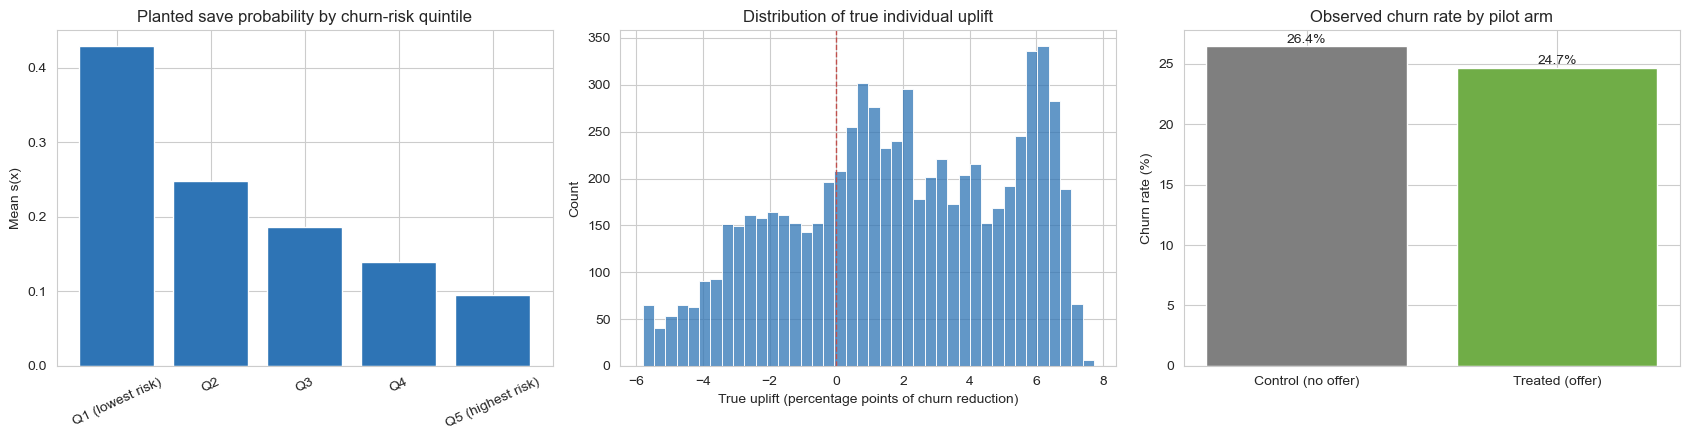

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

risk_quintile = pd.qcut(p0, 5, labels=["Q1 (lowest risk)", "Q2", "Q3", "Q4", "Q5 (highest risk)"])
save_by_risk = pd.Series(save_prob).groupby(risk_quintile, observed=True).mean()
axes[0].bar(save_by_risk.index, save_by_risk.values, color="#2E74B5")
axes[0].set_title("Planted save probability by churn-risk quintile")
axes[0].set_ylabel("Mean s(x)")
axes[0].tick_params(axis="x", rotation=25)

sns.histplot(sim["tau"] * 100, bins=40, color="#2E74B5", ax=axes[1])
axes[1].axvline(0, color="#C0504D", linestyle="--", linewidth=1)
axes[1].set_title("Distribution of true individual uplift")
axes[1].set_xlabel("True uplift (percentage points of churn reduction)")

observed_by_arm = pd.DataFrame({"W": sim["W"], "Y": sim["Y"]}).groupby("W")["Y"].mean() * 100
axes[2].bar(["Control (no offer)", "Treated (offer)"], observed_by_arm.values, color=["#7F7F7F", "#70AD47"])
axes[2].set_title("Observed churn rate by pilot arm")
axes[2].set_ylabel("Churn rate (%)")
for i, v in enumerate(observed_by_arm.values):
    axes[2].text(i, v + 0.3, f"{v:.1f}%", ha="center")

plt.tight_layout()
plt.show()


The synthetic uplift analysis demonstrates that the simulated probability of saving a customer decreases across churn-risk quintiles, from approximately 43% in Q1 (lowest risk) to 9% in Q5 (highest risk), highlighting that customers most likely to churn are not necessarily the easiest to retain. The distribution of true individual uplift shows heterogeneous treatment effects, with both positive and negative values, indicating that the simulated offer may reduce churn for some customers but have little or potentially adverse effects for others. The observed churn rate was 26.4% in the control group compared with 24.7% in the treated group, an absolute reduction of 1.7 percentage points (approximately 6.4% relative reduction). These findings illustrate the potential value of targeting customers based on their responsiveness to retention interventions rather than churn risk alone. However, because treatment assignment and individual uplift are simulated, the results demonstrate the methodology rather than establish real-world causal effects.